In [1]:
import numpy as np
from scipy.special import jn_zeros
from scipy.optimize import root_scalar, brentq
import matplotlib.pyplot as plt
from scipy.special import jv, jn_zeros
from scipy.integrate import quad
from joblib import Parallel, delayed

# Solución de la ecuación de difusión del modelo de dos regiones (_Two-Region Model_)

In [2]:
# Parámetros físicos
D1 = 0.5e9           # nm²/s (región superficial)
D2 = 2e9             # nm²/s (región volumétrica)
z_c = 10             # nm (altura de la interfaz)
L = 100              # nm (altura total)
R = 1000             # nm (radio del cilindro)
kappa = 1            # nm/s coeficiente de absorción superficial
n_modes_radial = 16  # Número de modos radiales
m_max = 16           # Número de modos axiales por modo radial
N_z = 1000           # Número de nodos en z

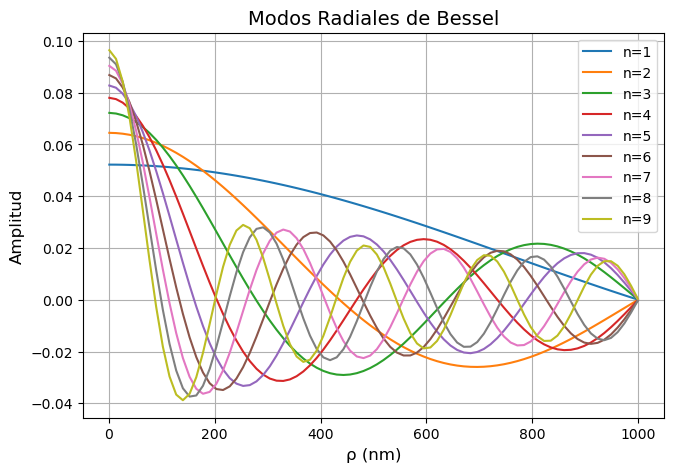

In [3]:
##############################################################################
# 1. Solución Radial R(ρ)
##############################################################################
# Cálculo de modos radiales
alpha_zeros = jn_zeros(0, n_modes_radial)
alpha_n = alpha_zeros / R  # Vector de α_n
rho_vals = np.linspace(0.001 * R, 0.999 * R, 80)  # 80 puntos en ρ

# Normalización de modos radiales
R_norms = np.sqrt((R**2 / 2) * jv(1, alpha_zeros)**2)  # ∫₀ᴿ J₀²(αₙρ) ρ dρ = R² J₁²(j₀ₙ)/2

# Evaluar funciones radiales normalizadas en rho_plot
J0_values = np.array([jv(0, alpha_n[n] * rho_vals) / np.sqrt(R_norms[n]) 
                     for n in range(n_modes_radial)])

# Graficar modos radiales
plt.figure(figsize=(7.5,5))
for n in range(min(9, n_modes_radial)):
    plt.plot(rho_vals, J0_values[n], label=f"n={n+1}", linewidth=1.5)

plt.xlabel("ρ (nm)", fontsize=12)
plt.ylabel("Amplitud", fontsize=12)
plt.title("Modos Radiales de Bessel", fontsize=14)
plt.legend()
plt.grid(True)
plt.savefig("figuras/modos_radiales.pdf", bbox_inches="tight")
plt.show()
plt.close()

In [4]:
##############################################################################
# 2. Ecuación trascendental
##############################################################################
def transcendental_eq(Lambda, alpha_n):
    beta_1_sq = (Lambda**2 - alpha_n**2 * D1) / D1
    beta_2_sq = (Lambda**2 - alpha_n**2 * D2) / D2
    
    # if beta_1_sq < 0 or beta_2_sq < 0:
    #     return np.inf  # Evitar raíces complejas
    
    beta_1 = np.sqrt(beta_1_sq)
    beta_2 = np.sqrt(beta_2_sq)
    
    # Ecuación con κ=0 simplificada
    return (D1 * beta_1*np.cos(beta_2*(L-z_c))-kappa*D2*beta_2/D1/beta_1*np.sin(beta_2*(L-z_c))) * np.sin(beta_1 * z_c) + (kappa**beta_1*np.cos(beta_2*(L-z_c))+D2 * beta_2*np.sin(beta_2 * (L - z_c))) * np.cos(beta_1 * z_c)

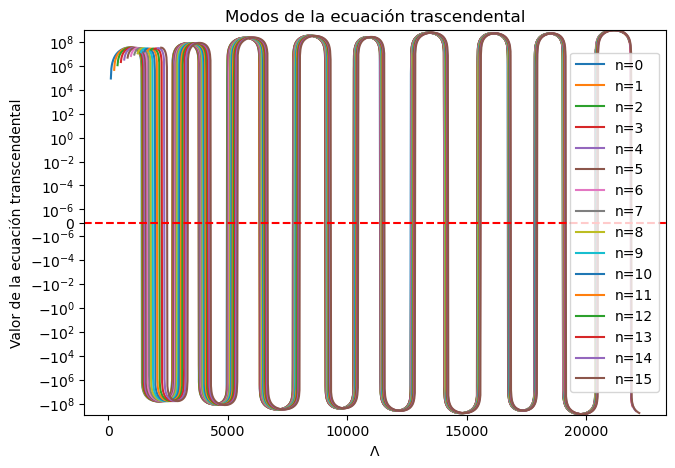

In [5]:
plt.figure(figsize=(7.5,5))
for n in range(n_modes_radial):
    Lambda=np.linspace(alpha_n[n]*np.sqrt(D2)+1e-3,2e4+alpha_n[n]*np.sqrt(D2)+1e-3,1000)
    plt.plot(Lambda,transcendental_eq(Lambda,alpha_n[n]),label=f'n={n}')
plt.legend()
plt.title("Modos de la ecuación trascendental")
plt.ylabel("Valor de la ecuación transcendental")
plt.xlabel(r"$\Lambda$")
plt.axhline(0, color='red', linestyle='--')
plt.yscale('symlog', linthresh=1e-6)

In [6]:
##############################################################################
# 3. Búsqueda de autovalores Λ para un α_n dado
##############################################################################

def find_m_roots(alpha, Lambda_max=5e4):
    Lambda_min = alpha * np.sqrt(D2)+1e-3
    roots = []
    step = 0.1  # Paso inicial para buscar raíces
    
    Lambda_current = Lambda_min
    while len(roots) < m_max and Lambda_current < Lambda_max:
        # Buscar raíces en el intervalo [Lambda_current, Lambda_current + step]
        try:
            root = brentq(transcendental_eq, Lambda_current, Lambda_current + step,
                           args=(alpha), xtol=1e-6)
            roots.append(root)
            Lambda_current = root + step  # Mover el inicio para la próxima búsqueda
        except ValueError:
            Lambda_current += step
    
    return roots[:m_max]  # Devuelve hasta m_max raíces

axial_results = Parallel(n_jobs=4, verbose=1)(delayed(find_m_roots)(alpha) for n, alpha in enumerate(alpha_n))
# Encontrar raíces para cada αₙ hasta m_max
eigenvalues_ax = {}
for n,alpha in enumerate(alpha_n):
    eigenvalues_ax[n] = axial_results[n]

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  16 out of  16 | elapsed:   50.7s finished


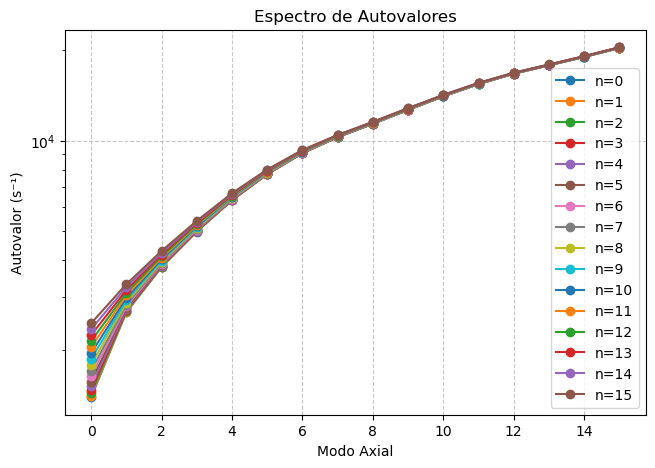

In [7]:
# Graficar espectro de autovalores
plt.figure(figsize=(7.5,5))
for n in range(n_modes_radial):
    evals = eigenvalues_ax[n]
    plt.semilogy(evals, 'o-', label=f'n={n}')
plt.xlabel('Modo Axial')
plt.ylabel('Autovalor (s⁻¹)')
plt.title('Espectro de Autovalores')
plt.legend()
plt.grid(ls='--', alpha=0.7)
plt.savefig('figuras/eigenvalues_tworegion.pdf', bbox_inches='tight')
plt.show()
plt.close()

## Cálculo de la constante $B$ de las funciones $Z_1(z)$ y $Z_2(z)$

Las funciones $Z_1(z)$ y $Z_2(z)$ se encuentran multiplicadas por una constante $B$.

$$Z_1(z)=B\left[\cos{(\beta_1z)}-\frac{\kappa}{D_1\beta_1}\sin{(\beta_1z)}\right]$$

$$Z_2(z)=B\left[\cos{(\beta_1z_c)}-\frac{\kappa}{D_1\beta_1}\sin{(\beta_1z_c)}\right]\left\{\tan{\left[\beta_2\left(L-z_c\right)\right]}\sin{\left[\beta_2\left(z-z_c\right)\right]}+\cos{\left[\beta_2\left(z-z_c\right)\right]}\right\}$$

Se debe cumplir que

$$\int_0^LZ^2(z)dz=1$$

Por lo que es posible separar la integral en los dos dominios de integración:

$$\int_0^{z_c}Z_1^2(z)dz+\int_{z_c}^LZ_2^2(z)dz=1$$

Se llama como $f_{1}(z)=\frac{Z_1(z)}{B}=\cos{(\beta_1z)}-\frac{\kappa}{D_1\beta_1}\sin{(\beta_1z)}$ y $f_{2}(z)=\frac{Z_2(z)}{B}=\left[\cos{(\beta_1z_c)}-\frac{\kappa}{D_1\beta_1}\sin{(\beta_1z_c)}\right]\left\{\tan{\left[\beta_2\left(L-z_c\right)\right]}\sin{\left[\beta_2\left(z-z_c\right)\right]}+\cos{\left[\beta_2\left(z-z_c\right)\right]}\right\}$

De forma que la integral queda como:

$$B^2\left(\int_0^{z_c}f_1^2(z)dz+\int_{z_c}^Lf_2^2(z)dz\right)=1$$

Y al despejar $B$:

$$B=\frac{1}{\sqrt{\int_0^{z_c}f_1^2(z)dz+\int_{z_c}^Lf_2^2(z)dz}}$$


De forma que $B$ depende de los modos radiales y axiales; sin embargo, se puede integrar el cálclo de los coeficientes $A_n$, $B_{n,m}$ y $T_{n,m}$ en una sola solución

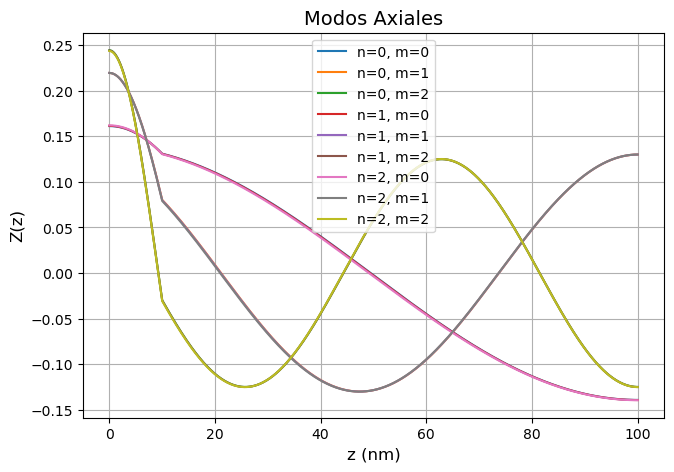

In [8]:
##############################################################################
# 4. Z(z) sin coeficientes
##############################################################################
z=np.linspace(0,L,N_z)
def fz_raw(z_val,n,m): # 2(z,r_mode,z_mode):
    """
    Devuelve Z(z)^2 para todo el dominio [0, L], dependiendo de la región.
    """
    r_mode=alpha_n[n]
    z_mode=eigenvalues_ax[n][m]
    
    beta_1 = np.sqrt((z_mode**2 - r_mode**2 * D1) / D1)
    beta_2 = np.sqrt((z_mode**2 - r_mode**2 * D2) / D2)

    if z_val<=z_c:
        Z = np.cos(beta_1 * z_val) - (kappa / (D1 * beta_1)) * np.sin(beta_1 * z_val)
    else:
        Z = (np.cos(beta_1 * z_c) - (kappa / (D1 * beta_1)) * np.sin(beta_1 * z_c)) * (np.tan(beta_2 * (L - z_c)) * np.sin(beta_2 * (z_val - z_c)) + np.cos(beta_2 * (z_val - z_c)))
    return Z

# discretización en z
z = np.linspace(0, L, N_z)

# precomputar constantes de normalización C_nm
C_nm = np.zeros((n_modes_radial, m_max))
for n in range(n_modes_radial):
    for m in range(m_max):
        Z_vals = np.array([fz_raw(z_val, n, m) for z_val in z])
        integral = np.trapz(Z_vals**2, z)      # ∫0^L Z^2 dz
        C_nm[n, m] = 1.0 / np.sqrt(integral)   # factor de normalización

# ahora definimos la función normalizada
def fz(z_val, n, m):
    return C_nm[n, m] * fz_raw(z_val, n, m)

plt.figure(figsize=(7.5,5))
for n in range(3):
    for m in range(3):
        Zs=[]
        for z_val in z:
            Zs.append(fz(z_val,n,m))
        plt.plot(z,np.array(Zs), label=f"n={n}, m={m}", linewidth=1.5)
plt.xlabel("z (nm)", fontsize=12)
plt.ylabel("Z(z)", fontsize=12)
plt.title("Modos Axiales", fontsize=14)
plt.legend()
plt.grid(True)
plt.savefig("figuras/modos_axiales_tworegion.pdf", bbox_inches="tight")
plt.show()
plt.close()    

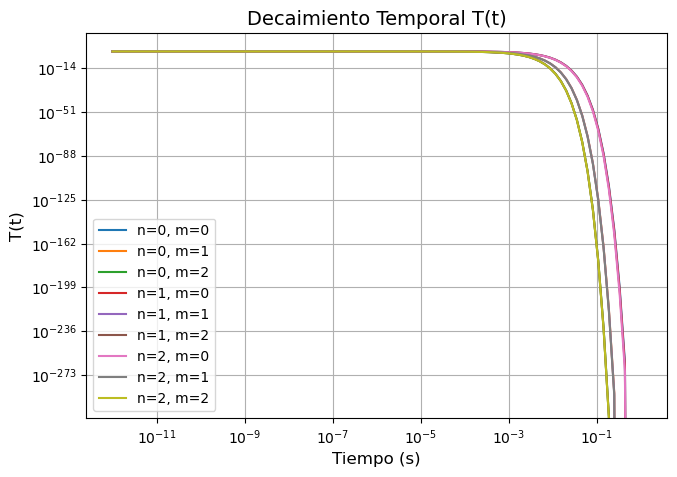

In [9]:
##############################################################################
# 5. Término Temporal T(t)
##############################################################################
# Ahora, para cada eigenvalor (de la parte axial) usaremos el valor absoluto
# para que T(t)=exp(-|λ| t) decaiga.
def T(t, lam):
    return np.exp(-np.abs(lam) * t)

# Graficamos T(t) para los modos del sistema axial
plt.figure(figsize=(7.5,5))
t_plot = np.logspace(-12, 0, 100)
for n in range(min(3,n_modes_radial)):
    for m in range(min(3, m_max)):
        lam = eigenvalues_ax[n][m]
        plt.loglog(t_plot, T(t_plot, lam), label=f"n={n}, m={m}", linewidth=1.5)
plt.xlabel("Tiempo (s)", fontsize=12)
plt.ylabel("T(t)", fontsize=12)
plt.title("Decaimiento Temporal T(t)", fontsize=14)
plt.legend()
plt.grid(True, which="both")
plt.savefig("figuras/T_t_tworegion.pdf", bbox_inches="tight")
plt.show()
plt.close()

In [10]:
##############################################################################
# 6. Cálculo de Coeficientes A_{nm}
##############################################################################
# Se asume que la condición inicial es:
#     P(ρ, z, 0) ∝ δ(ρ-ρ0) δ(z-z0) / (2πρ0)
# Con ρ0 = 750 nm y z0 = 10 nm.
rho0 = 750  # nm
z0 = 10     # nm

def compute_A_nm(n):
    """Calcula A_{n,m} para un modo radial fijo n."""
    A_nm = np.zeros(m_max)
    alpha = alpha_n[n]
    R_norm = np.sqrt((R**2 / 2) * jv(1, alpha_n[n]*R)**2)  # ‖R_n‖
    
    for m in range(m_max):
               
        # 1. Evaluar Z_{n,m}(z0)
        Z_z0 = fz(z0,n,m)
        
        # 2. Evaluar R_n(ρ0)
        R_rho0 = jv(0, alpha*rho0)
        
        # 3. Calcular A_{n,m}
        A_nm[m] = (R_rho0 * Z_z0) / (2 * np.pi * R_norm)
    
    return A_nm

# Cálculo paralelizado
A_nm = Parallel(n_jobs=4)(delayed(compute_A_nm)(n) for n in range(n_modes_radial))

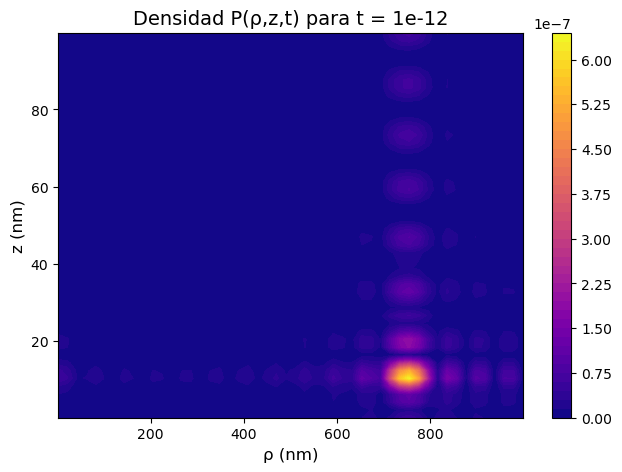

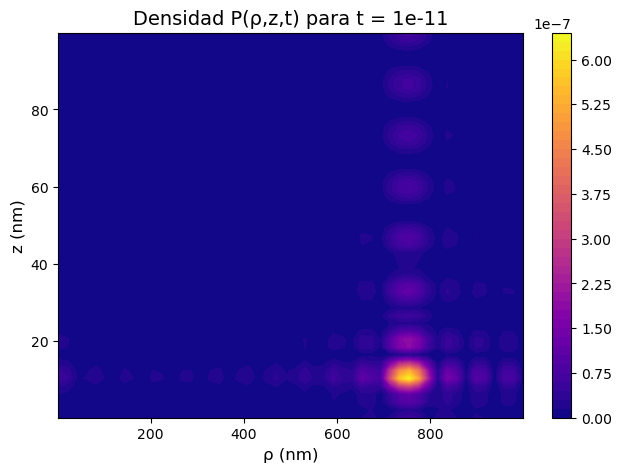

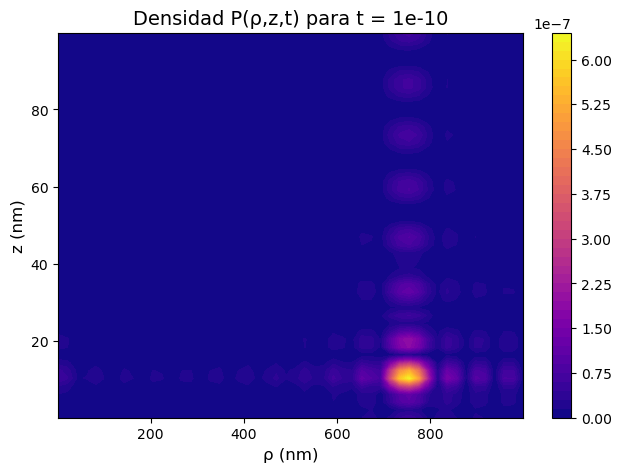

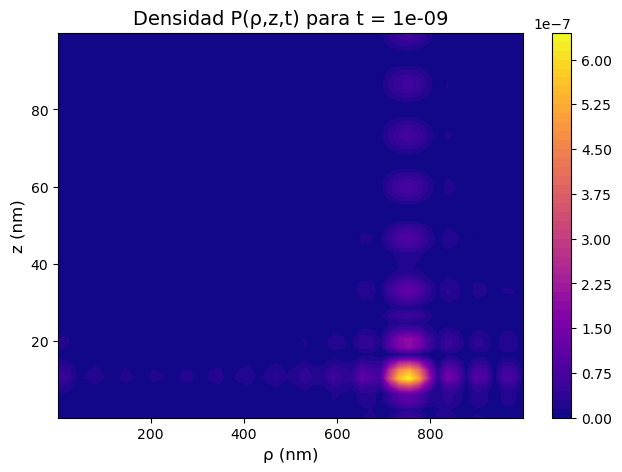

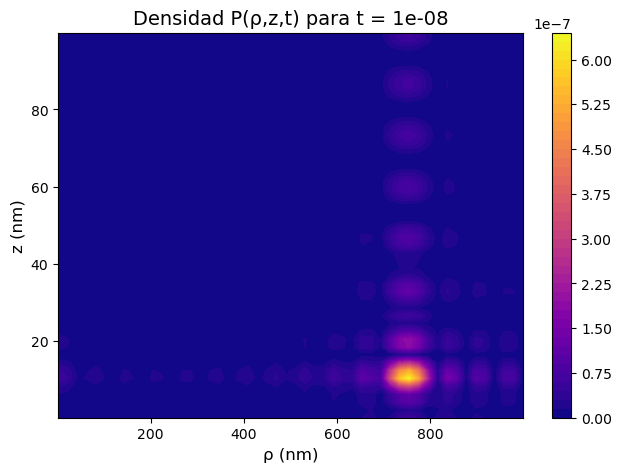

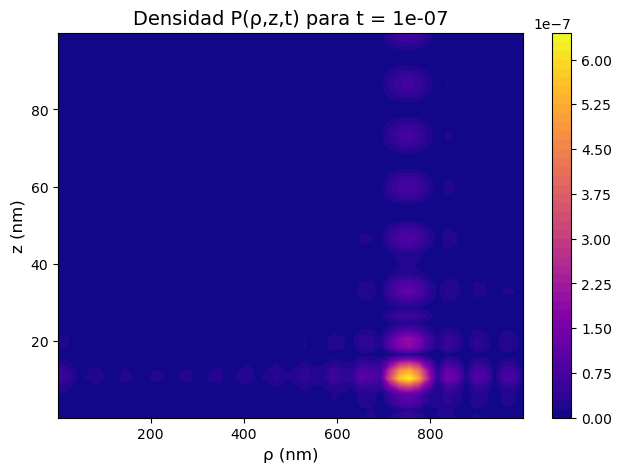

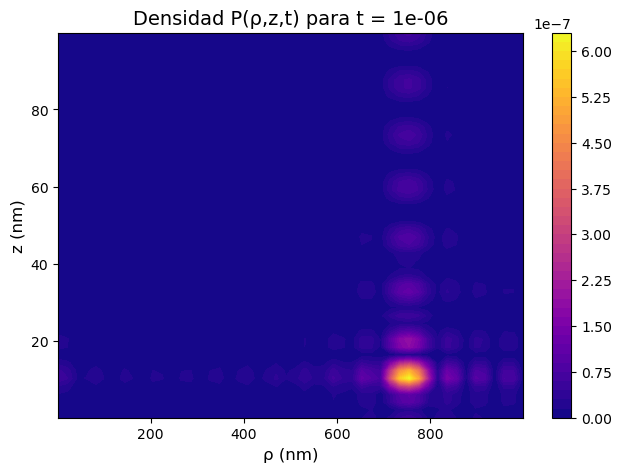

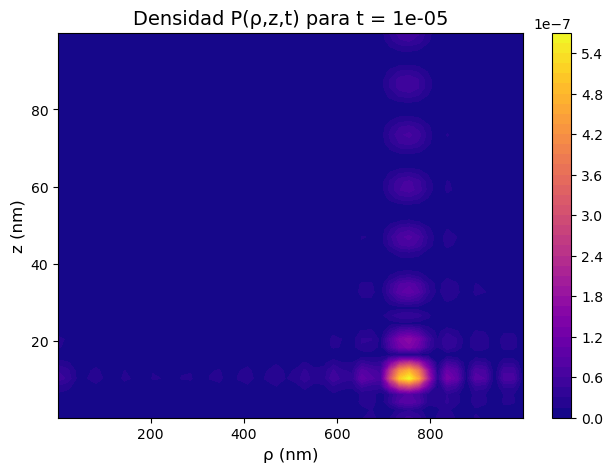

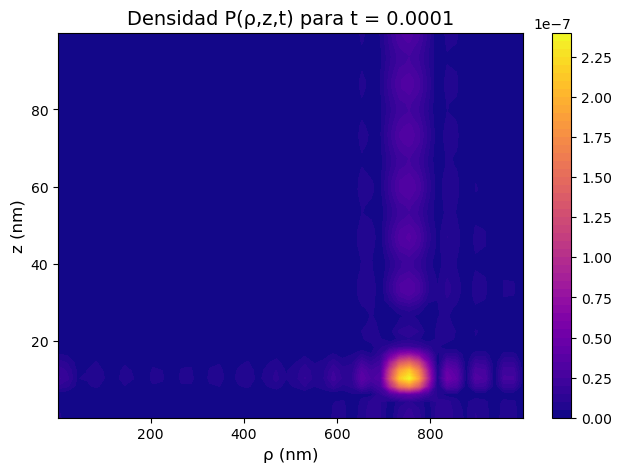

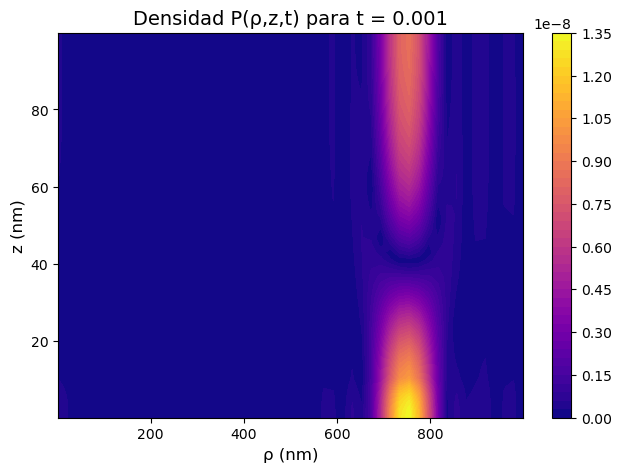

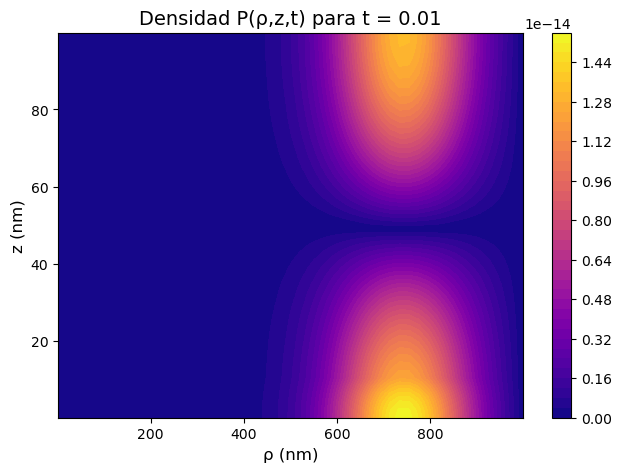

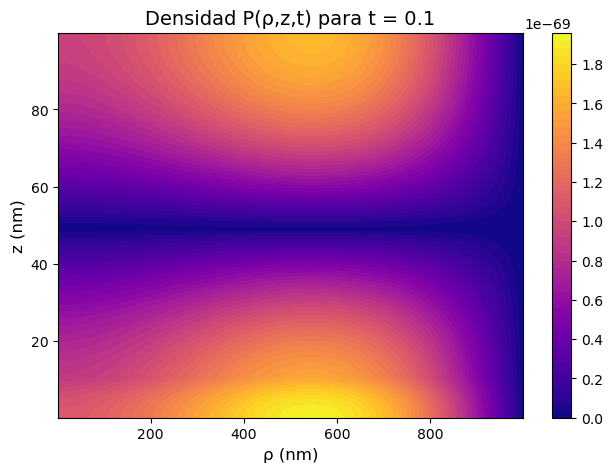

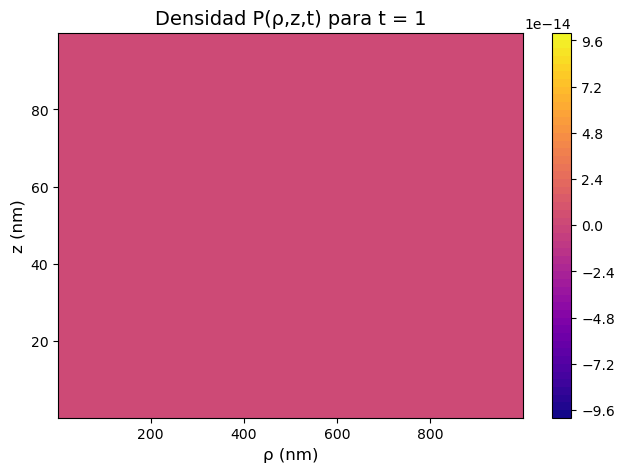

In [11]:
##############################################################################
## # 7. Densidad de Probabilidad P(ρ,z,t)
##############################################################################
def compute_P(rho_vals, z_vals, t):
    P = np.zeros((len(z_vals), len(rho_vals)))
    # Para cada modo se usa T_{n,m}(t)= exp(-|λ_{n,m}|t)
    for i, rho in enumerate(rho_vals):
        J0_vals = jv(0, alpha_n * rho)
        for j, z_val in enumerate(z_vals):
            s = 0.0
            for n in range(n_modes_radial):
                for m in range(m_max):
                    Z_val = fz(z_val,n,m)
                    T_val = np.exp(np.clip(-np.abs(eigenvalues_ax[n][m]) * t, -700, 700))
                    s += A_nm[n][m] * J0_vals[n]/R_norms[n] * Z_val * T_val
            P[j, i] = np.abs(s)
    return P

rho_vals = np.linspace(0.001 * R, 0.999 * R, 50)
z_vals = np.linspace(0.001*L, 0.999*L, 50)
for t_val in [1e-12,1e-11,1e-10,1e-9,1e-8,1e-7,1e-6,1e-5,1e-4,1e-3,1e-2,1e-1,1]:
    P_val = compute_P(rho_vals, z_vals, t=t_val)
    
    plt.figure(figsize=(7.5,5))
    plt.contourf(rho_vals, z_vals, P_val, 50, cmap="plasma")
    plt.xlabel("ρ (nm)", fontsize=12)
    plt.ylabel("z (nm)", fontsize=12)
    plt.title(f"Densidad P(ρ,z,t) para t = {t_val}", fontsize=14)
    plt.colorbar()
    plt.savefig(f"figuras/P_contour_tworegion_{t_val}.pdf", bbox_inches="tight")
    plt.show()
    plt.close()

In [12]:
s = 0.0
for n in range(n_modes_radial):
    for m in range(m_max):
        s += (
            A_nm[n][m]
            * jv(0, alpha_n[n] * rho0) / R_norms[n]
            * fz(z0,n,m)
        )
print("s =", s, " vs 1/(2πρ0) =", 1/(2*np.pi*rho0))

s = 6.320449815306628e-07  vs 1/(2πρ0) = 0.0002122065907891938


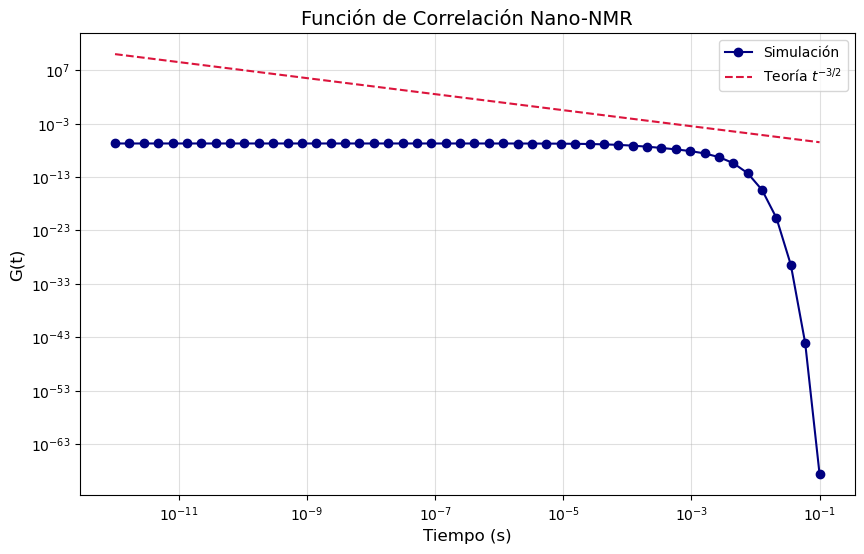

In [13]:
##############################################################################
# 8. Función de Correlación G(t)
##############################################################################
def compute_G(t, N_quad=40):
    # Dominios en nm: ρ en [0.3R, 0.7R] y z en [9,11] nm.
    
    # Mallado uniforme en rho y z
    rho_nodes = np.linspace(0.65 * R, 0.85 * R, N_quad)
    z_nodes = np.linspace(7, 13, N_quad)
    total = 0.0
    for rho in rho_nodes:
        J0_vals = jv(0, alpha_n * rho)
        for j,z_val in enumerate(z_nodes):
            f = (3 * z_val**2 - rho**2) / (rho**2 + z_val**2 + 1e-30)**2.5
            s = 0.0
            for n in range(n_modes_radial):
                for m in range(m_max):
                    Z_val = fz(z_val,n,m)
                    T_val = np.exp(np.clip(-np.abs(eigenvalues_ax[n][m]) * t, -700, 700))
                    s += A_nm[n][m] * J0_vals[n] * Z_val * T_val
            total += np.abs(rho*f*s)
    dr = (0.9 * R - 0.1 * R) / N_quad
    result = (5 / (16 * np.pi)) * (total * dr)
    return result

t_values = np.logspace(-12, -1, 50)
G_values = Parallel(n_jobs=4)(delayed(compute_G)(t) for t in t_values)

np.savetxt("data/G_vs_t_tworegion.dat", np.c_[t_values, G_values], header="Tiempo(s) G(t)", fmt="%.3e")

plt.figure(figsize=(10,6))
plt.loglog(t_values, G_values, "o-", label="Simulación", color="navy", markersize=6, linewidth=1.5)
plt.plot(t_values, 1e-8 * t_values**-1.5, "--", label=r"Teoría $t^{-3/2}$", color="crimson", linewidth=1.5)
plt.xlabel("Tiempo (s)", fontsize=12)
plt.ylabel("G(t)", fontsize=12)
plt.title("Función de Correlación Nano-NMR", fontsize=14)
plt.legend()
plt.grid(which="both", alpha=0.4)
plt.savefig("figuras/correlacion_nanoNMR_tworegion.pdf", bbox_inches="tight", dpi=300)
plt.show()
plt.close()